In [1]:
# Cellule 1 — Imports
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG19, ResNet50, MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import warnings
warnings.filterwarnings('ignore')

print("TensorFlow version:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU disponible: []


In [ ]:
# Cellule 2 — Téléchargement du dataset
# Le dataset sera téléchargé manuellement depuis Kaggle.
# Si le dossier chest_xray/ existe déjà, cette cellule est ignorée.

import zipfile

DATASET_DIR = 'chest_xray'
ZIP_FILE = 'chest-xray-pneumonia.zip'

if not os.path.exists(DATASET_DIR):
    if not os.path.exists(ZIP_FILE):
        print("=" * 60)
        print("TÉLÉCHARGEMENT MANUEL REQUIS")
        print("=" * 60)
        print()
        print("1. Allez sur : https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia")
        print("2. Cliquez sur le bouton 'Download' (vous devez être connecté à Kaggle)")
        print(f"3. Placez le fichier '{ZIP_FILE}' dans :")
        print(f"   {os.path.abspath('.')}")
        print()
        print("4. Puis ré-exécutez cette cellule.")
        print("=" * 60)
        raise FileNotFoundError(f"Fichier '{ZIP_FILE}' non trouvé. Suivez les instructions ci-dessus.")

    print("Extraction du dataset...")
    with zipfile.ZipFile(ZIP_FILE, 'r') as zip_ref:
        zip_ref.extractall(DATASET_DIR)
    print("Extraction terminée.")
else:
    print(f"Le dossier '{DATASET_DIR}' existe déjà, téléchargement ignoré.")

VALID_EXTS = ('.jpeg', '.jpg', '.png', '.bmp', '.tif', '.tiff')

def count_valid_images(path):
    return len([f for f in os.listdir(path) if f.lower().endswith(VALID_EXTS)])

for split in ['train', 'val', 'test']:
    for cls in ['NORMAL', 'PNEUMONIA']:
        path = f'chest_xray/chest_xray/{split}/{cls}'
        if os.path.exists(path):
            count = count_valid_images(path)
            print(f"{split}/{cls}: {count} images")

Le dossier 'chest_xray' existe déjà, téléchargement ignoré.
train/NORMAL: 1341 images
train/PNEUMONIA: 3875 images
val/NORMAL: 8 images
val/PNEUMONIA: 8 images
test/NORMAL: 234 images
test/PNEUMONIA: 390 images


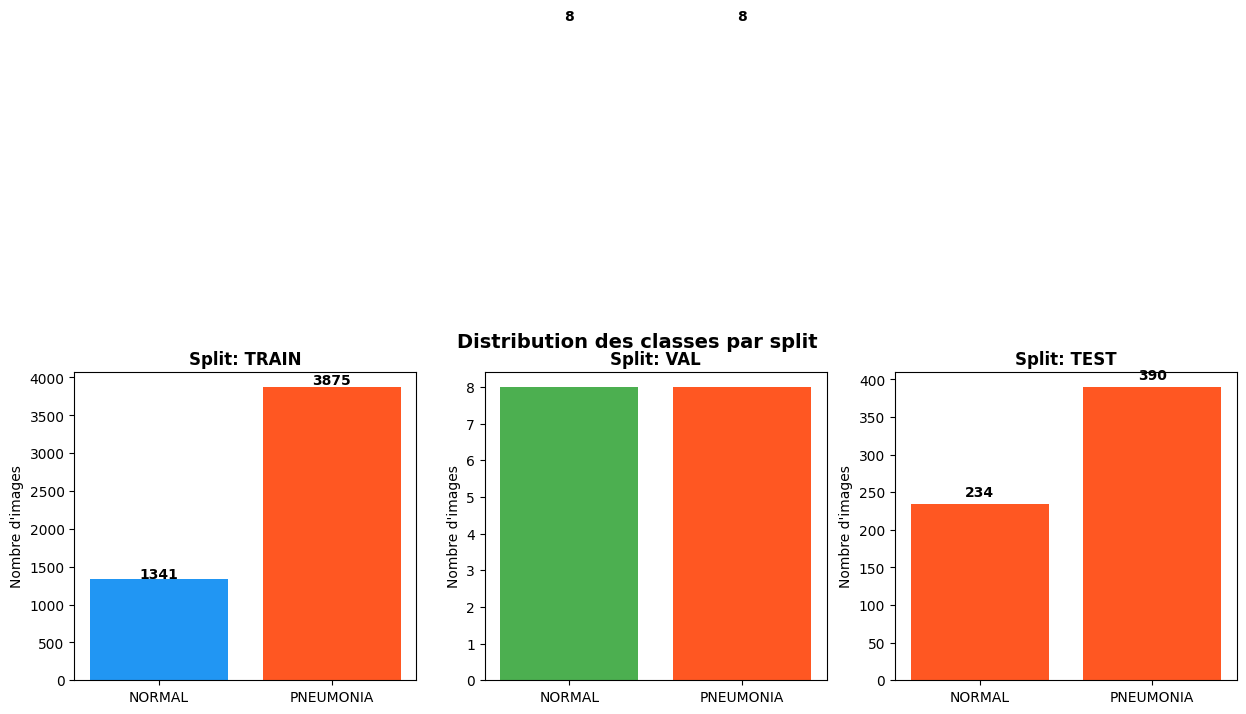


Déséquilibre train: 2.9x plus de PNEUMONIA que NORMAL


In [ ]:
# Cellule 3 — Visualisation de la distribution des classes
BASE_DIR = 'chest_xray/chest_xray'
VALID_EXTS = ('.jpeg', '.jpg', '.png', '.bmp', '.tif', '.tiff')

def count_valid_images(path):
    return len([f for f in os.listdir(path) if f.lower().endswith(VALID_EXTS)])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
splits = ['train', 'val', 'test']
colors = ['#2196F3', '#4CAF50', '#FF5722']

train_normal = train_pneumonia = 1
for i, (split, color) in enumerate(zip(splits, colors)):
    normal = count_valid_images(f'{BASE_DIR}/{split}/NORMAL')
    pneumonia = count_valid_images(f'{BASE_DIR}/{split}/PNEUMONIA')

    if split == 'train':
        train_normal, train_pneumonia = normal, pneumonia

    axes[i].bar(['NORMAL', 'PNEUMONIA'], [normal, pneumonia], color=[color, '#FF5722'])
    axes[i].set_title(f'Split: {split.upper()}', fontweight='bold')
    axes[i].set_ylabel("Nombre d'images")
    for j, v in enumerate([normal, pneumonia]):
        axes[i].text(j, v + max(10, int(v * 0.01)), str(v), ha='center', fontweight='bold')

plt.suptitle('Distribution des classes par split', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

if train_normal > 0:
    print(f"\nDéséquilibre train: {train_pneumonia / train_normal:.1f}x plus de PNEUMONIA que NORMAL")

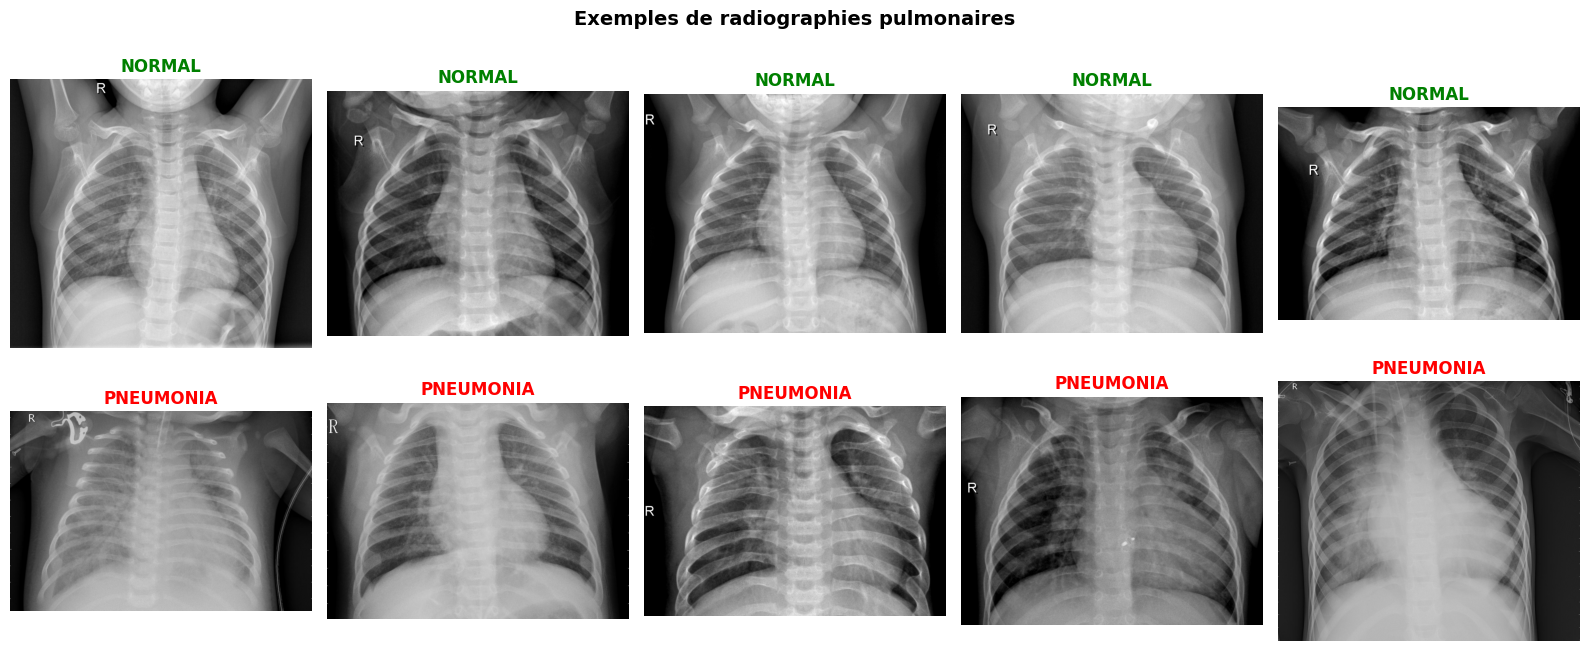

In [ ]:
# Cellule 4 — Affichage d'exemples d'images
from PIL import Image

VALID_EXTS = ('.jpeg', '.jpg', '.png', '.bmp', '.tif', '.tiff')

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
classes = ['NORMAL', 'PNEUMONIA']

for row, cls in enumerate(classes):
    img_dir = f'{BASE_DIR}/train/{cls}'
    imgs = [f for f in os.listdir(img_dir) if f.lower().endswith(VALID_EXTS)][:5]

    for col, img_name in enumerate(imgs):
        img = Image.open(f'{img_dir}/{img_name}').convert('L')
        axes[row][col].imshow(img, cmap='gray')
        axes[row][col].set_title(cls,
                                  color='green' if cls == 'NORMAL' else 'red',
                                  fontweight='bold')
        axes[row][col].axis('off')

plt.suptitle('Exemples de radiographies pulmonaires', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Cellule 5 — Configuration des générateurs
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    f'{BASE_DIR}/train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True
)

val_gen = val_test_datagen.flow_from_directory(
    f'{BASE_DIR}/val',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

test_gen = val_test_datagen.flow_from_directory(
    f'{BASE_DIR}/test',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

print("Classes:", train_gen.class_indices)
print(f"Train: {train_gen.samples} images")
print(f"Val: {val_gen.samples} images")
print(f"Test: {test_gen.samples} images")

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Classes: {'NORMAL': 0, 'PNEUMONIA': 1}
Train: 5216 images
Val: 16 images
Test: 624 images


Found 5216 images belonging to 2 classes.


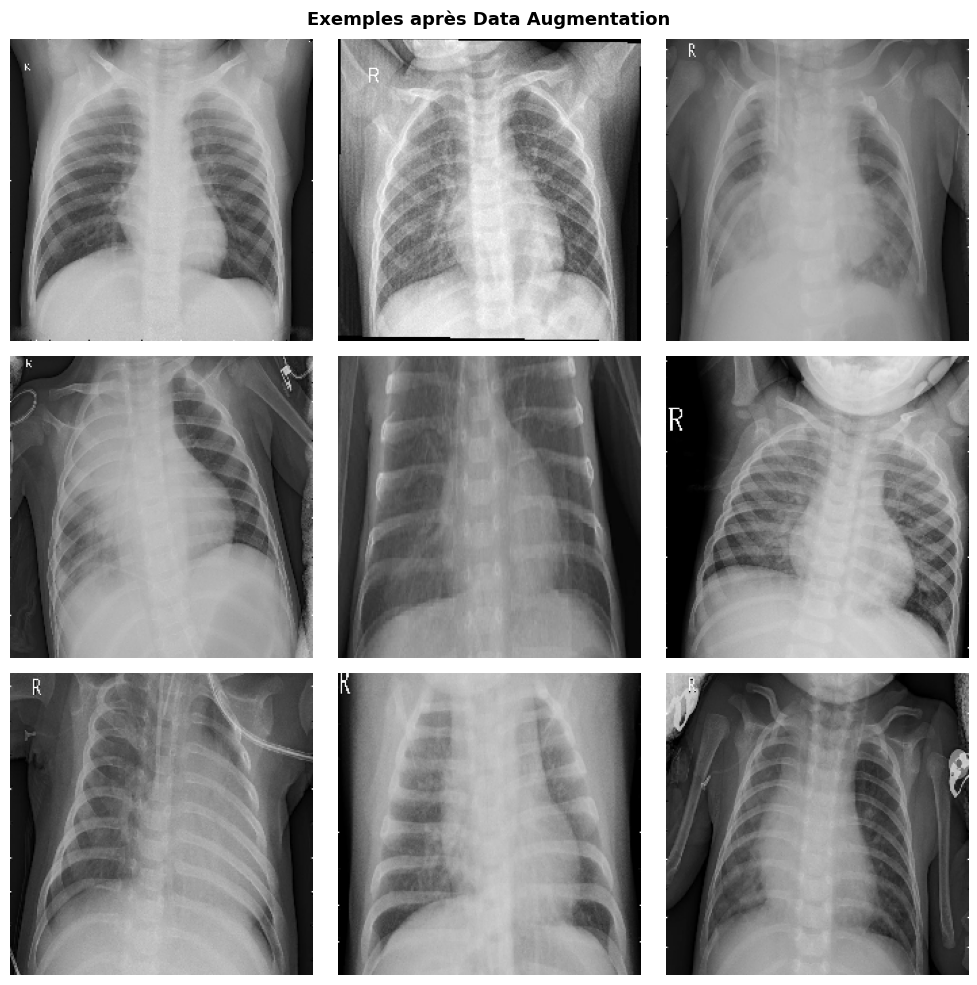

In [ ]:
# Cellule 6 — Visualisation des augmentations
# Correction : on utilise train_datagen (avec augmentation) et non val_test_datagen
sample_gen = train_datagen.flow_from_directory(
    f'{BASE_DIR}/train',
    target_size=IMG_SIZE,
    batch_size=9,
    shuffle=True
)

sample_imgs = next(sample_gen)[0]

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    ax.imshow(sample_imgs[i])
    ax.axis('off')

plt.suptitle('Exemples après Data Augmentation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Cellule 7 — Construction du modèle CNN avec Transfer Learning
def build_model(base_model_name='VGG19', fine_tune=False):
    input_shape = (224, 224, 3)

    if base_model_name == 'VGG19':
        base = VGG19(weights='imagenet', include_top=False, input_shape=input_shape)
    elif base_model_name == 'ResNet50':
        base = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    elif base_model_name == 'MobileNetV2':
        base = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)

    base.trainable = False

    if fine_tune:
        for layer in base.layers[-20:]:
            layer.trainable = True

    model = keras.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.BatchNormalization(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy',
                 keras.metrics.Precision(name='precision'),
                 keras.metrics.Recall(name='recall'),
                 keras.metrics.AUC(name='auc')]
    )

    return model

# Création du modèle VGG19
model = build_model('VGG19', fine_tune=False)
model.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1101s 14us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 7, 7, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,190,785 (77.02 MB)

 Trainable params: 165,377 (646.00 KB)

 Non-trainable params: 20,025,408 (76.39 MB)

In [ ]:
# Cellule 8 — Entraînement Phase 1 (Feature Extraction)
from sklearn.utils.class_weight import compute_class_weight

# Gestion du déséquilibre des classes
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=train_gen.classes
)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}
print("Poids des classes:", class_weight_dict)

# Callbacks
callbacks = [
    EarlyStopping(monitor='val_loss', patience=7,
                  restore_best_weights=True, verbose=1),
    ModelCheckpoint('best_model_vgg19.h5', monitor='val_accuracy',
                    save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=3, min_lr=1e-7, verbose=1)
]

# Entraînement
history_phase1 = model.fit(
    train_gen,
    epochs=20,
    validation_data=val_gen,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

Poids des classes: {0: np.float64(1.9448173005219984), 1: np.float64(0.6730322580645162)}
Epoch 1/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7449 - auc: 0.7510 - loss: 0.5786 - precision: 0.8644 - recall: 0.7850
Epoch 1: val_accuracy improved from None to 0.75000, saving model to best_model_vgg19.h5



Epoch 1: finished saving model to best_model_vgg19.h5
163/163 ━━━━━━━━━━━━━━━━━━━━ 716s 4s/step - accuracy: 0.7926 - auc: 0.8640 - loss: 0.4642 - precision: 0.9126 - recall: 0.7972 - val_accuracy: 0.7500 - val_auc: 0.8828 - val_loss: 0.6119 - val_precision: 0.7500 - val_recall: 0.7500 - learning_rate: 1.0000e-04
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8520 - auc: 0.9257 - loss: 0.3492 - precision: 0.9509 - recall: 0.8438
Epoch 2: val_accuracy did not improve from 0.75000
163/163 ━━━━━━━━━━━━━━━━━━━━ 514s 3s/step - accuracy: 0.8683 - auc: 0.9383 - loss: 0.3183 - precision: 0.9594 - recall: 0.8591 - val_accuracy: 0.6875 - val_auc: 0.9062 - val_loss: 0.4741 - val_precision: 0.6667 - val_recall: 0.7500 - learning_rate: 1.0000e-04
Epoch 3/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8823 - auc: 0.9505 - loss: 0.2821 - precision: 0.9616 - recall: 0.8778
Epoch 3: val_accuracy did not improve from 0.75000
163/163 ━━━━━━━━━━━━━━━━━━━━ 514s 3s/step - accurac


Epoch 4: finished saving model to best_model_vgg19.h5
163/163 ━━━━━━━━━━━━━━━━━━━━ 510s 3s/step - accuracy: 0.8972 - auc: 0.9581 - loss: 0.2591 - precision: 0.9654 - recall: 0.8937 - val_accuracy: 0.8125 - val_auc: 0.9375 - val_loss: 0.3576 - val_precision: 0.7273 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 5/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8968 - auc: 0.9617 - loss: 0.2482 - precision: 0.9648 - recall: 0.8949
Epoch 5: val_accuracy improved from 0.81250 to 0.87500, saving model to best_model_vgg19.h5



Epoch 5: finished saving model to best_model_vgg19.h5
163/163 ━━━━━━━━━━━━━━━━━━━━ 514s 3s/step - accuracy: 0.9005 - auc: 0.9652 - loss: 0.2375 - precision: 0.9687 - recall: 0.8950 - val_accuracy: 0.8750 - val_auc: 0.9375 - val_loss: 0.3525 - val_precision: 0.8000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 6/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9171 - auc: 0.9717 - loss: 0.2108 - precision: 0.9768 - recall: 0.9104
Epoch 6: val_accuracy did not improve from 0.87500
163/163 ━━━━━━━━━━━━━━━━━━━━ 511s 3s/step - accuracy: 0.9118 - auc: 0.9702 - loss: 0.2165 - precision: 0.9744 - recall: 0.9050 - val_accuracy: 0.8750 - val_auc: 0.9375 - val_loss: 0.3308 - val_precision: 0.8000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 7/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9131 - auc: 0.9747 - loss: 0.2029 - precision: 0.9707 - recall: 0.9111
Epoch 7: val_accuracy did not improve from 0.87500
163/163 ━━━━━━━━━━━━━━━━━━━━ 509s 3s/step - accurac

In [ ]:
# Sauvegarde du modèle (vérification)
if os.path.exists('best_model_vgg19.h5'):
    print(f"Modèle best_model_vgg19.h5 sauvegardé localement ({os.path.getsize('best_model_vgg19.h5') / 1e6:.1f} MB)")
else:
    print("Attention : best_model_vgg19.h5 non trouvé")

Modèle best_model_vgg19.h5 sauvegardé localement (82.2 MB)


In [ ]:
# Cellule 9 — Fine-tuning Phase 2
model_ft = build_model('VGG19', fine_tune=True)
model_ft.load_weights('best_model_vgg19.h5')

model_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall'),
             keras.metrics.AUC(name='auc')]
)

callbacks_ft = [
    EarlyStopping(monitor='val_loss', patience=5,
                  restore_best_weights=True, verbose=1),
    ModelCheckpoint('best_model_vgg19_ft.h5', monitor='val_accuracy',
                    save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=3, min_lr=1e-7, verbose=1)
]

history_phase2 = model_ft.fit(
    train_gen,
    epochs=15,
    validation_data=val_gen,
    class_weight=class_weight_dict,
    callbacks=callbacks_ft,
    verbose=1
)

Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.9211 - auc: 0.9700 - loss: 0.2196 - precision: 0.9800 - recall: 0.9111 
Epoch 1: val_accuracy improved from None to 0.87500, saving model to best_model_vgg19_ft.h5



Epoch 1: finished saving model to best_model_vgg19_ft.h5
163/163 ━━━━━━━━━━━━━━━━━━━━ 1909s 12s/step - accuracy: 0.9323 - auc: 0.9803 - loss: 0.1752 - precision: 0.9841 - recall: 0.9239 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.2309 - val_precision: 0.8000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.9499 - auc: 0.9895 - loss: 0.1272 - precision: 0.9883 - recall: 0.9449 
Epoch 2: val_accuracy did not improve from 0.87500
163/163 ━━━━━━━━━━━━━━━━━━━━ 1980s 12s/step - accuracy: 0.9525 - auc: 0.9899 - loss: 0.1239 - precision: 0.9887 - recall: 0.9468 - val_accuracy: 0.8125 - val_auc: 0.9766 - val_loss: 0.4889 - val_precision: 1.0000 - val_recall: 0.6250 - learning_rate: 1.0000e-05
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 17s/step - accuracy: 0.9590 - auc: 0.9891 - loss: 0.1200 - precision: 0.9901 - recall: 0.9543 
Epoch 3: val_accuracy did not improve from 0.87500
163/163 ━━━━━━━━━━━━━━━━━━━━ 2759s 17s/s


Epoch 4: finished saving model to best_model_vgg19_ft.h5
163/163 ━━━━━━━━━━━━━━━━━━━━ 1901s 12s/step - accuracy: 0.9651 - auc: 0.9928 - loss: 0.0988 - precision: 0.9915 - recall: 0.9613 - val_accuracy: 0.9375 - val_auc: 0.9844 - val_loss: 0.1512 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 1.0000e-05
Epoch 5/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.9712 - auc: 0.9959 - loss: 0.0713 - precision: 0.9935 - recall: 0.9677 
Epoch 5: val_accuracy did not improve from 0.93750
163/163 ━━━━━━━━━━━━━━━━━━━━ 1898s 12s/step - accuracy: 0.9724 - auc: 0.9956 - loss: 0.0719 - precision: 0.9934 - recall: 0.9693 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.1125 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 1.0000e-05
Epoch 6/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.9684 - auc: 0.9957 - loss: 0.0784 - precision: 0.9921 - recall: 0.9648 
Epoch 6: val_accuracy did not improve from 0.93750
163/163 ━━━━━━━━━━━━━━━━━━━━ 1897s 12s/s


Epoch 9: finished saving model to best_model_vgg19_ft.h5
163/163 ━━━━━━━━━━━━━━━━━━━━ 1890s 12s/step - accuracy: 0.9826 - auc: 0.9981 - loss: 0.0486 - precision: 0.9968 - recall: 0.9796 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0109 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 5.0000e-06
Epoch 10/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.9793 - auc: 0.9972 - loss: 0.0532 - precision: 0.9962 - recall: 0.9761 
Epoch 10: val_accuracy did not improve from 1.00000
163/163 ━━━━━━━━━━━━━━━━━━━━ 1883s 12s/step - accuracy: 0.9812 - auc: 0.9980 - loss: 0.0481 - precision: 0.9968 - recall: 0.9778 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0485 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 5.0000e-06
Epoch 11/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.9861 - auc: 0.9985 - loss: 0.0393 - precision: 0.9951 - recall: 0.9861 
Epoch 11: val_accuracy did not improve from 1.00000
163/163 ━━━━━━━━━━━━━━━━━━━━ 1884s 1

In [ ]:
# Vérification des modèles sauvegardés localement
for fname in ['best_model_vgg19.h5', 'best_model_vgg19_ft.h5']:
    if os.path.exists(fname):
        print(f"{fname} sauvegardé ({os.path.getsize(fname) / 1e6:.1f} MB)")
    else:
        print(f"Attention : {fname} non trouvé")

best_model_vgg19.h5 sauvegardé (82.2 MB)
best_model_vgg19_ft.h5 sauvegardé (242.4 MB)


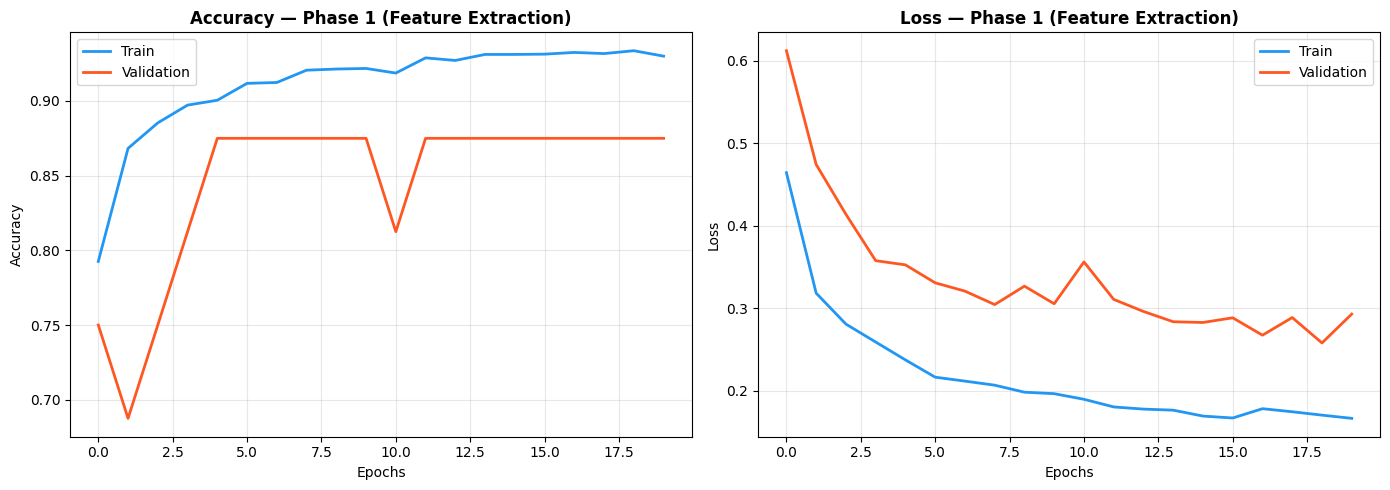

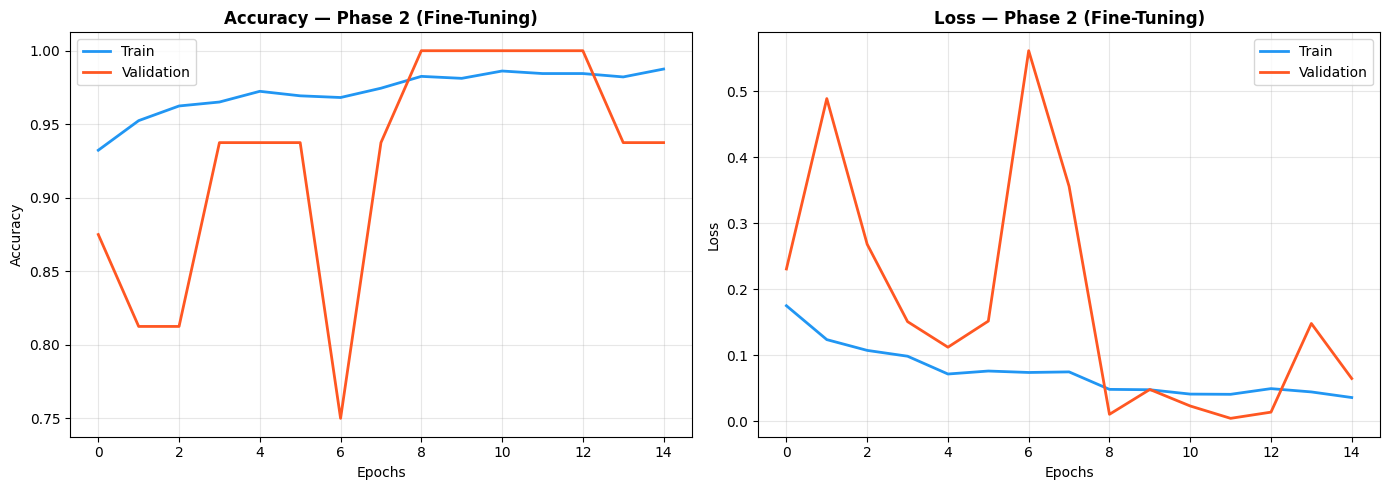

In [ ]:
# Cellule 10 — Courbes d'apprentissage
def plot_training_history(history, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['accuracy'],
                 label='Train', color='#2196F3', linewidth=2)
    axes[0].plot(history.history['val_accuracy'],
                 label='Validation', color='#FF5722', linewidth=2)
    axes[0].set_title(f'Accuracy {title}', fontweight='bold')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history['loss'],
                 label='Train', color='#2196F3', linewidth=2)
    axes[1].plot(history.history['val_loss'],
                 label='Validation', color='#FF5722', linewidth=2)
    axes[1].set_title(f'Loss {title}', fontweight='bold')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_training_history(history_phase1, '— Phase 1 (Feature Extraction)')
plot_training_history(history_phase2, '— Phase 2 (Fine-Tuning)')

In [ ]:
# Cellule 11 — Évaluation sur le jeu de test
best_model = keras.models.load_model('best_model_vgg19_ft.h5')

# Prédictions
test_gen.reset()
y_pred_prob = best_model.predict(test_gen, verbose=1)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
y_true = test_gen.classes

# Rapport de classification
print("\n" + "="*50)
print("RAPPORT DE CLASSIFICATION")
print("="*50)
print(classification_report(y_true, y_pred,
      target_names=['NORMAL', 'PNEUMONIA']))

# Métriques globales
test_loss, test_acc, test_prec, test_rec, test_auc = best_model.evaluate(
    test_gen, verbose=1)
f1 = 2 * (test_prec * test_rec) / (test_prec + test_rec)

print("\n" + "="*50)
print("MÉTRIQUES FINALES SUR TEST")
print("="*50)
print(f"Accuracy  : {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Precision : {test_prec:.4f}")
print(f"Recall    : {test_rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"AUC       : {test_auc:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 61s 3s/step

RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

      NORMAL       0.97      0.82      0.89       234
   PNEUMONIA       0.90      0.98      0.94       390

    accuracy                           0.92       624
   macro avg       0.94      0.90      0.92       624
weighted avg       0.93      0.92      0.92       624

20/20 ━━━━━━━━━━━━━━━━━━━━ 61s 3s/step - accuracy: 0.9247 - auc: 0.9750 - loss: 0.2384 - precision: 0.9035 - recall: 0.9846

MÉTRIQUES FINALES SUR TEST
Accuracy  : 0.9247 (92.47%)
Precision : 0.9035
Recall    : 0.9846
F1-Score  : 0.9423
AUC       : 0.9750


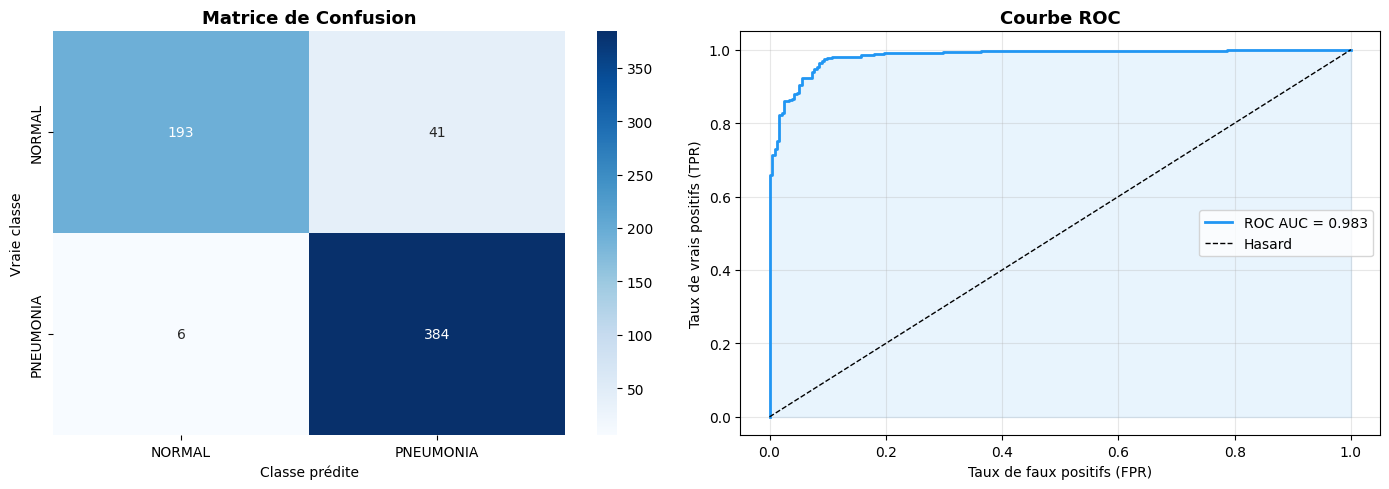


Vrais Négatifs  (NORMAL correct)     : 193
Faux Positifs   (NORMAL → PNEUMONIA) : 41
Faux Négatifs   (PNEUMONIA → NORMAL) : 6
Vrais Positifs  (PNEUMONIA correct)  : 384


In [ ]:
# Cellule 12 — Matrice de confusion + Courbe ROC
cm = confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matrice de confusion
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['NORMAL', 'PNEUMONIA'],
            yticklabels=['NORMAL', 'PNEUMONIA'])
axes[0].set_title('Matrice de Confusion', fontweight='bold', fontsize=13)
axes[0].set_ylabel('Vraie classe')
axes[0].set_xlabel('Classe prédite')

# Courbe ROC
fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='#2196F3', lw=2,
             label=f'ROC AUC = {roc_auc:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Hasard')
axes[1].fill_between(fpr, tpr, alpha=0.1, color='#2196F3')
axes[1].set_title('Courbe ROC', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Taux de faux positifs (FPR)')
axes[1].set_ylabel('Taux de vrais positifs (TPR)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('evaluation_results.png', dpi=150, bbox_inches='tight')
plt.show()

# Afficher les détails de la matrice
tn, fp, fn, tp = cm.ravel()
print(f"\nVrais Négatifs  (NORMAL correct)     : {tn}")
print(f"Faux Positifs   (NORMAL → PNEUMONIA) : {fp}")
print(f"Faux Négatifs   (PNEUMONIA → NORMAL) : {fn}")
print(f"Vrais Positifs  (PNEUMONIA correct)  : {tp}")

In [ ]:
print("Résultats d'évaluation sauvegardés localement")

Résultats d'évaluation sauvegardés localement


In [ ]:
# Les modèles sont déjà sauvegardés localement dans le dossier courant
for fname in ['best_model_vgg19.h5', 'best_model_vgg19_ft.h5']:
    if os.path.exists(fname):
        print(f"{fname} disponible localement ({os.path.getsize(fname) / 1e6:.1f} MB)")
    else:
        print(f"{fname} non trouvé")

best_model_vgg19.h5 disponible localement (82.2 MB)
best_model_vgg19_ft.h5 disponible localement (242.4 MB)



Entraînement de VGG19...
VGG19 — Accuracy: 0.649 | F1: 0.7808

Entraînement de ResNet50...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 215s 2us/step
ResNet50 — Accuracy: 0.8446 | F1: 0.8677

Entraînement de MobileNetV2...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 19s 2us/step
MobileNetV2 — Accuracy: 0.6506 | F1: 0.7816

TABLEAU COMPARATIF DES MODÈLES
             Accuracy  Precision  Recall  F1-Score
VGG19          0.6490     0.6404  1.0000    0.7808
ResNet50       0.8446     0.9271  0.8154    0.8677
MobileNetV2    0.6506     0.6414  1.0000    0.7816


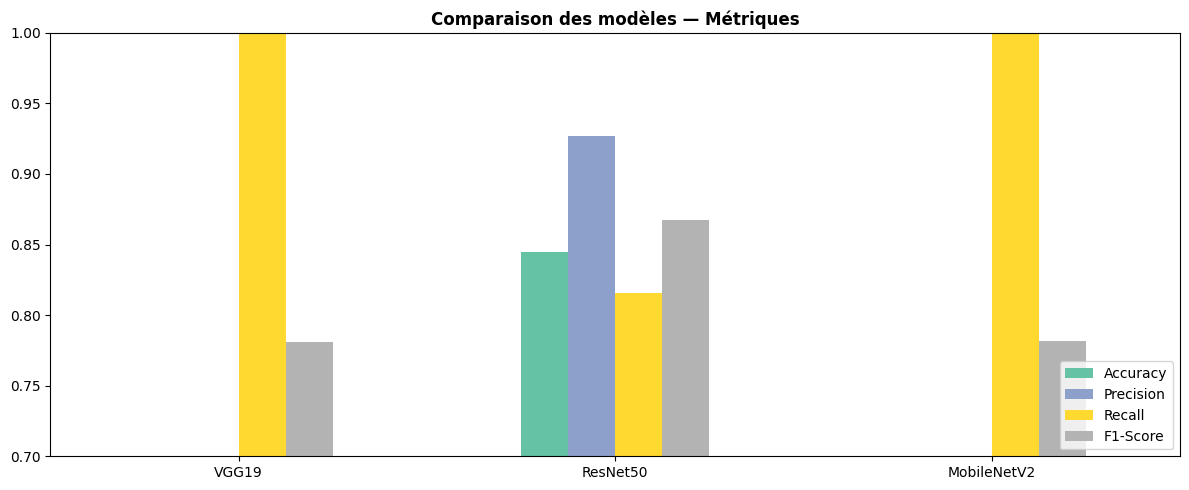

In [ ]:
# Cellule 13 — Comparaison VGG19 / ResNet50 / MobileNetV2
import pandas as pd
results = {}

for model_name in ['VGG19', 'ResNet50', 'MobileNetV2']:
    print(f"\n{'='*40}")
    print(f"Entraînement de {model_name}...")

    m = build_model(model_name, fine_tune=True)

    m.fit(
        train_gen,
        epochs=5,
        validation_data=val_gen,
        class_weight=class_weight_dict,
        callbacks=[EarlyStopping(patience=3, restore_best_weights=True)],
        verbose=0
    )

    # Évaluation sur test
    test_gen.reset()
    y_prob = m.predict(test_gen, verbose=0)
    y_p = (y_prob > 0.5).astype(int).flatten()
    y_t = test_gen.classes

    report = classification_report(y_t, y_p,
                                   target_names=['NORMAL', 'PNEUMONIA'],
                                   output_dict=True)

    results[model_name] = {
        'Accuracy'  : round(report['accuracy'], 4),
        'Precision' : round(report['PNEUMONIA']['precision'], 4),
        'Recall'    : round(report['PNEUMONIA']['recall'], 4),
        'F1-Score'  : round(report['PNEUMONIA']['f1-score'], 4),
    }
    print(f"{model_name} — Accuracy: {results[model_name]['Accuracy']} "
          f"| F1: {results[model_name]['F1-Score']}")

# Tableau comparatif
df_results = pd.DataFrame(results).T
print("\n" + "="*55)
print("TABLEAU COMPARATIF DES MODÈLES")
print("="*55)
print(df_results.to_string())

# Graphique comparatif
df_results.plot(kind='bar', figsize=(12, 5), colormap='Set2')
plt.title('Comparaison des modèles — Métriques', fontweight='bold')
plt.xticks(rotation=0)
plt.ylim(0.7, 1.0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()

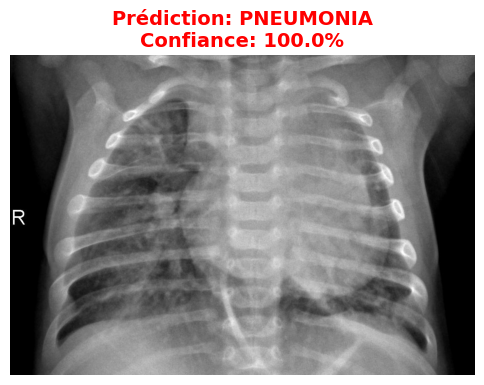

Résultat : PNEUMONIA (100.0% de confiance)


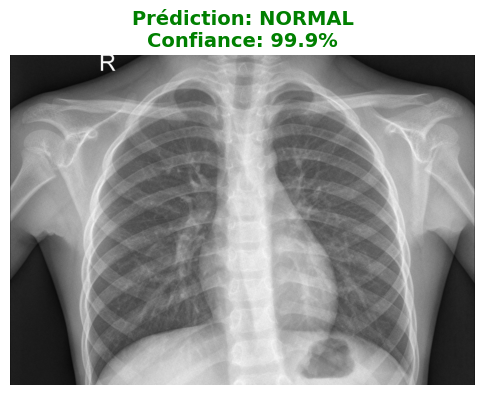

Résultat : NORMAL (99.9% de confiance)


In [ ]:
# Cellule 14 — Inférence sur une nouvelle image
from tensorflow.keras.preprocessing import image as keras_image

VALID_EXTS = ('.jpeg', '.jpg', '.png', '.bmp', '.tif', '.tiff')

def first_image_path(folder):
    files = [f for f in os.listdir(folder) if f.lower().endswith(VALID_EXTS)]
    if not files:
        raise FileNotFoundError(f"Aucune image valide trouvée dans {folder}")
    return os.path.join(folder, files[0])

def predict_xray(img_path, model, threshold=0.5):
    img = keras_image.load_img(img_path, target_size=(224, 224))
    img_array = keras_image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prob = model.predict(img_array, verbose=0)[0][0]
    classe = 'PNEUMONIA' if prob > threshold else 'NORMAL'
    confiance = prob if prob > threshold else 1 - prob

    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    ax.imshow(keras_image.load_img(img_path))
    color = 'red' if classe == 'PNEUMONIA' else 'green'
    ax.set_title(f'Prédiction: {classe}\nConfiance: {confiance*100:.1f}%',
                 color=color, fontsize=14, fontweight='bold')
    ax.axis('off')
    plt.show()

    return classe, confiance

# Test sur image PNEUMONIA
img_path = first_image_path(f'{BASE_DIR}/test/PNEUMONIA')
classe, confiance = predict_xray(img_path, best_model)
print(f"Résultat : {classe} ({confiance*100:.1f}% de confiance)")

# Test sur image NORMAL
img_path2 = first_image_path(f'{BASE_DIR}/test/NORMAL')
classe2, confiance2 = predict_xray(img_path2, best_model)
print(f"Résultat : {classe2} ({confiance2*100:.1f}% de confiance)")

In [ ]:
# Les modèles sont sauvegardés dans le dossier courant
print("Tous les modèles sont disponibles localement :")
for fname in ['best_model_vgg19.h5', 'best_model_vgg19_ft.h5']:
    if os.path.exists(fname):
        print(f"  - {fname} ({os.path.getsize(fname) / 1e6:.1f} MB)")
    else:
        print(f"  - {fname} (non trouvé)")

Tous les modèles sont disponibles localement :
  - best_model_vgg19.h5 (82.2 MB)
  - best_model_vgg19_ft.h5 (242.4 MB)
